#Titanic Case Overview

In this case study, we aim to predict passenger survival aboard the Titanic using various machine learning classification models. The dataset, sourced from Seaborn’s built-in Titanic dataset, includes a range of demographic and onboard information such as age, gender, ticket class, and embarkation point. The target variable is survived, where 0 indicates the passenger did not survive and 1 indicates survival.

This analysis follows a structured pipeline: data exploration, preprocessing, baseline modeling (without scaling), feature selection using KBest and LASSO, scaled modeling, and comprehensive evaluation. We will implement and evaluate multiple models including Logistic Regression, K-Nearest Neighbors (KNN), Decision Trees, Gaussian Naive Bayes, and LASSO regression. Each model will be assessed using accuracy, precision, recall, F1-score, and most importantly, the ROC-AUC score.

A special focus is placed on comparing baseline and scaled model performance to understand the effect of feature scaling. The end goal is to identify the most effective model for this classification task and gain actionable insights from the features that influence survival.

#Data Exploration

##Loading the Dataset

In [ ]:
import seaborn as sns
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import missingno as msno
import warnings
warnings.filterwarnings('ignore')

# Load the Titanic dataset
titanic = sns.load_dataset('titanic')

# Print the first few rows of the dataset
titanic.head(10)

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
5,0,3,male,NaN,0,0,8.4583,Q,Third,man,True,NaN,Queenstown,no,True
6,0,1,male,54.0,0,0,51.8625,S,First,man,True,E,Southampton,no,True
7,0,3,male,2.0,3,1,21.0750,S,Third,child,False,NaN,Southampton,no,False
8,1,3,female,27.0,0,2,11.1333,S,Third,woman,False,NaN,Southampton,yes,False
9,1,2,female,14.0,1,0,30.0708,C,Second,child,False,NaN,Cherbourg,yes,False


##Shape

In [ ]:
titanic.shape

(891, 15)

##Info

In [ ]:
titanic.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB


##Describe - Numerical Features

In [ ]:
titanic.describe()

,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


##Describe - Categorical Features

In [ ]:
titanic.describe(include=['O'])

,sex,embarked,who,embark_town,alive
count,891,889,891,889,891
unique,2,3,3,3,2
top,male,S,man,Southampton,no
freq,577,644,537,644,549


- The dataset contains 891 rows and 15 columns.
- Several columns have missing values (age, embarked, deck, and embark_town)
- The target column is survived.
- Many categorical columns such as sex, embarked, and class will need to be encoded before modeling.

##Missing Values Analysis

In [ ]:
# Total missing values per column
missing_count = titanic.isnull().sum()

# Percentage of missing values
missing_percent = (missing_count / len(titanic)) * 100

missing_df = pd.DataFrame({
    'Missing Count': missing_count,
    'Missing %': missing_percent
}).sort_values(by='Missing %', ascending=False)

missing_df

,Missing Count,Missing %
deck,688,77.216611
age,177,19.865320
embarked,2,0.224467
embark_town,2,0.224467
sex,0,0.000000
pclass,0,0.000000
survived,0,0.000000
fare,0,0.000000
parch,0,0.000000
sibsp,0,0.000000


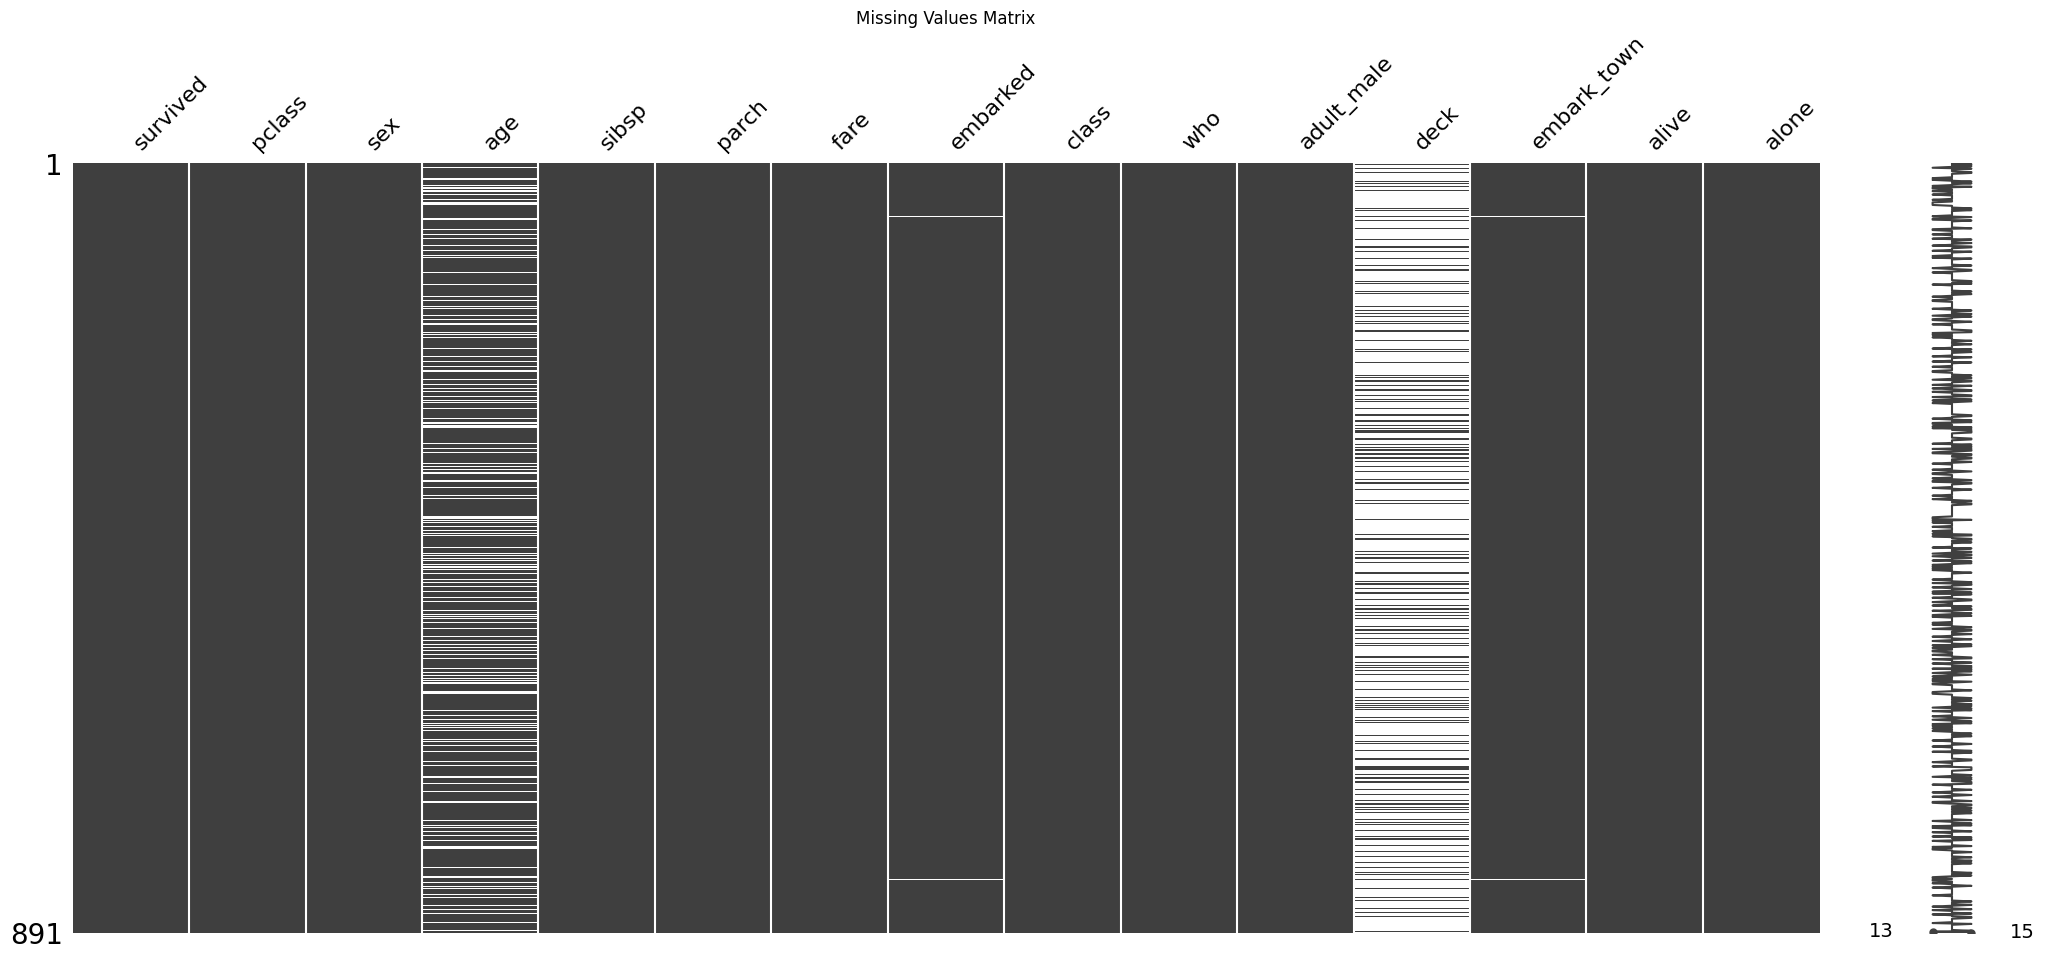

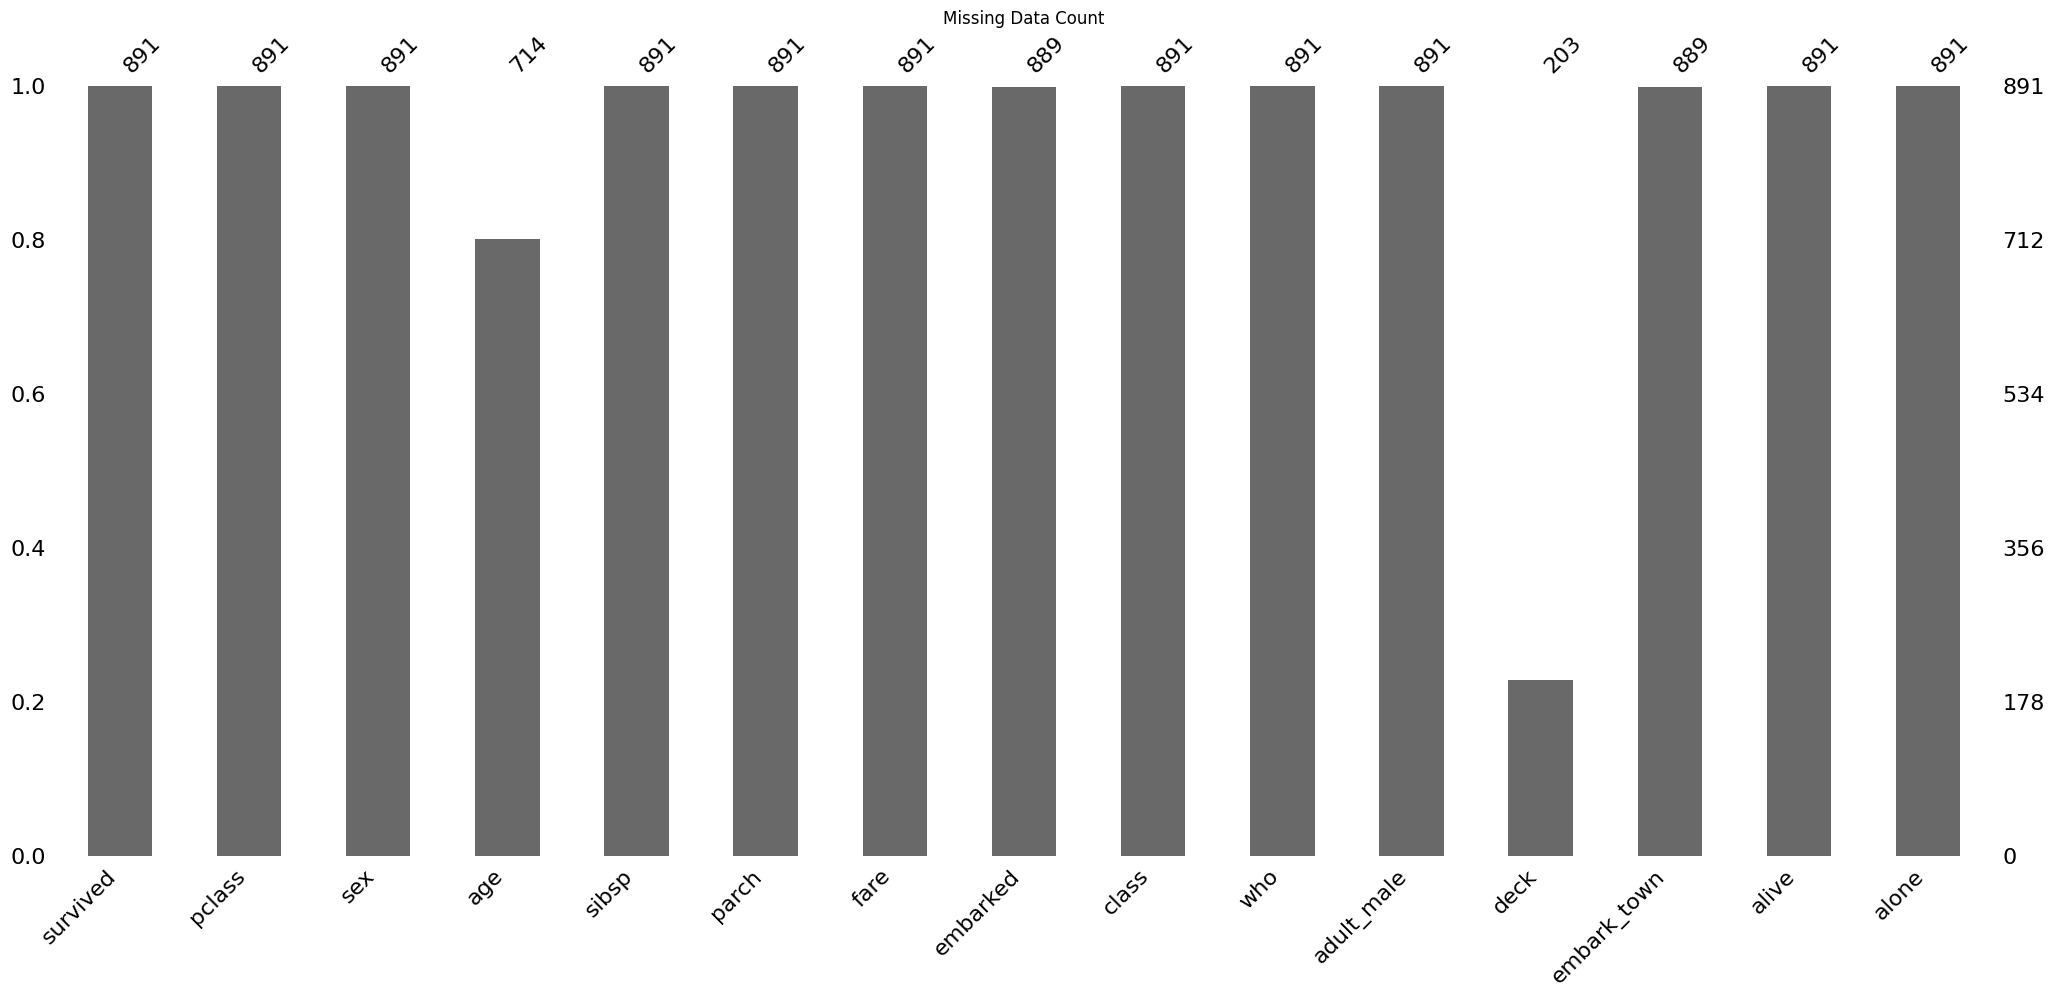

In [ ]:
# Visual heatmap of missing values
msno.matrix(titanic)
plt.title("Missing Values Matrix")
plt.show()

# Bar plot of missing values
msno.bar(titanic)
plt.title("Missing Data Count")
plt.show()

- Deck is missing ~77% of its data — Drop this column.
- Age has ~20% missing values — Fill this with the median.
- Embarked and embark_town have a few missing entries — Impute these using the mode.
- Alive is a duplicate of survived in text form — Drop it.

- I'm filling with median and mode because if i fill NAN with 0 it will mean that they are new born which is wrong



##DTypes

In [ ]:
titanic.dtypes

,0
survived,int64
pclass,int64
sex,object
age,float64
sibsp,int64
parch,int64
fare,float64
embarked,object
class,category
who,object


#EDA

##Univariate Analysis

###Distribution of Numerical Features

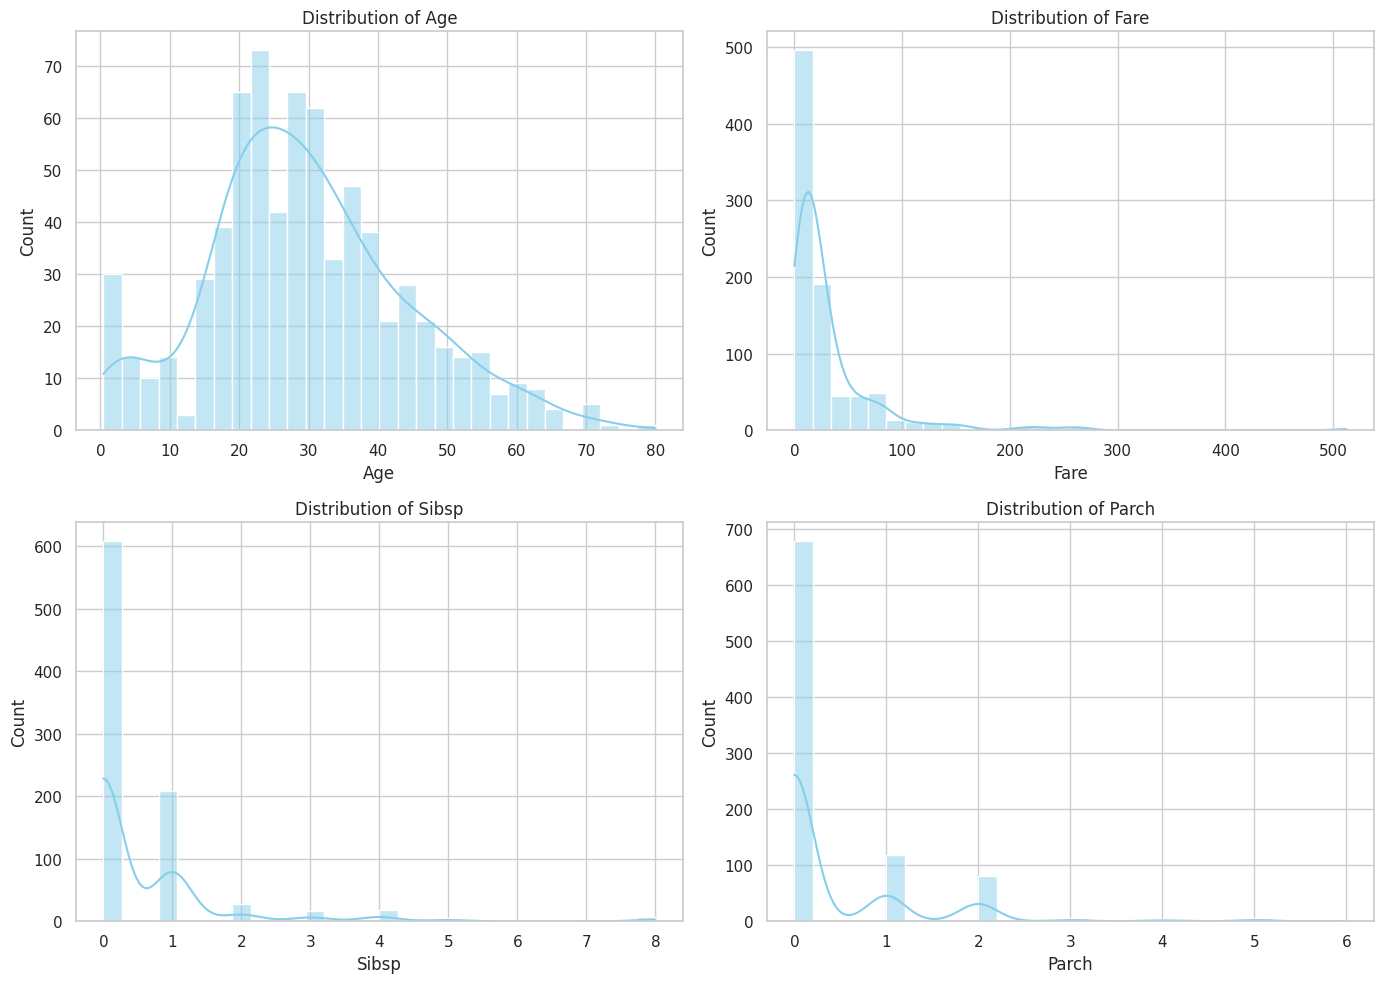

In [ ]:
# Set visual style
sns.set(style="whitegrid")

# Plot histograms for numerical variables
num_cols = ['age', 'fare', 'sibsp', 'parch']

# Create a grid of plots
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for idx, col in enumerate(num_cols):
    sns.histplot(titanic[col], bins=30, kde=True, ax=axes[idx], color='skyblue')
    axes[idx].set_title(f'Distribution of {col.capitalize()}')
    axes[idx].set_xlabel(col.capitalize())
    axes[idx].set_ylabel('Count')

plt.tight_layout()
plt.show()

###Categorical Feature Distributions

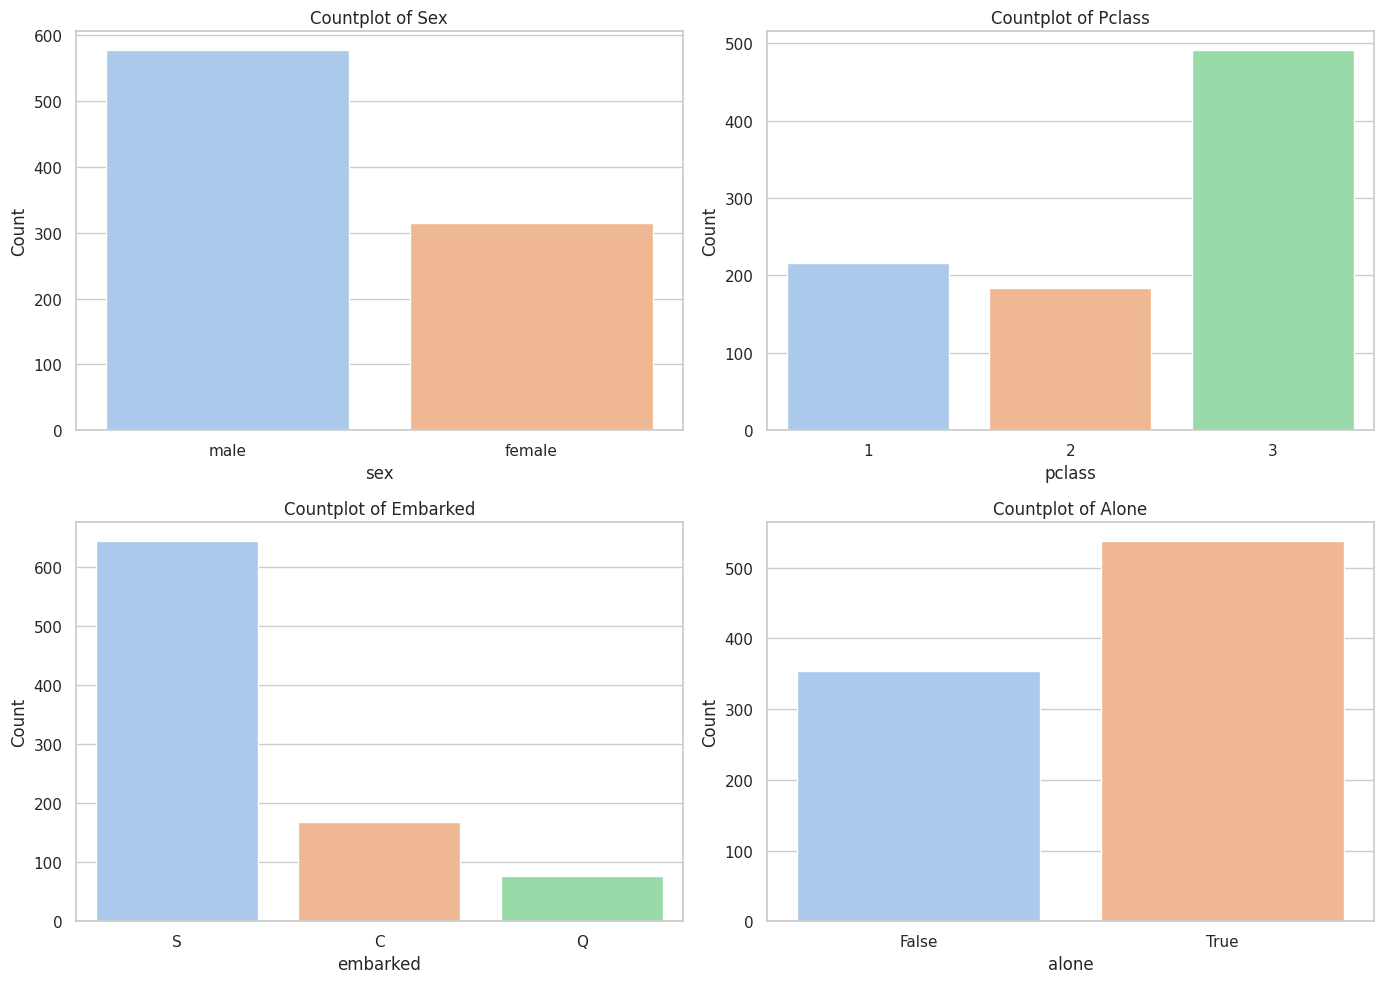

In [ ]:
# Categorical columns to visualize
cat_cols = ['sex', 'pclass', 'embarked', 'alone']

# Plot countplots for categorical variables
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for idx, col in enumerate(cat_cols):
    sns.countplot(data=titanic, x=col, palette='pastel', ax=axes[idx])
    axes[idx].set_title(f'Countplot of {col.capitalize()}')
    axes[idx].set_ylabel("Count")

plt.tight_layout()
plt.show()

The univariate analysis of the Titanic dataset reveals several key patterns in both numerical and categorical features. In terms of age, most passengers were young adults in their 20s and 30s, with a long right tail suggesting fewer older passengers. Fare prices were highly skewed to the right, with the majority of fares clustered below $100 but a few passengers paying as much as $500 — indicative of a small elite class. The number of siblings/spouses (sibsp) and parents/children (parch) aboard was low for most passengers, with a dominant count of zero, reflecting that many individuals traveled alone. For categorical variables, males significantly outnumbered females, and third class was the most common ticket type. Most passengers embarked from Southampton ('S'), and a large proportion of passengers were traveling alone. These distributions set the stage for understanding which variables may influence survival and provide context for deeper bivariate and multivariate analysis.

##Bivariate Analysis (Survival vs Features)

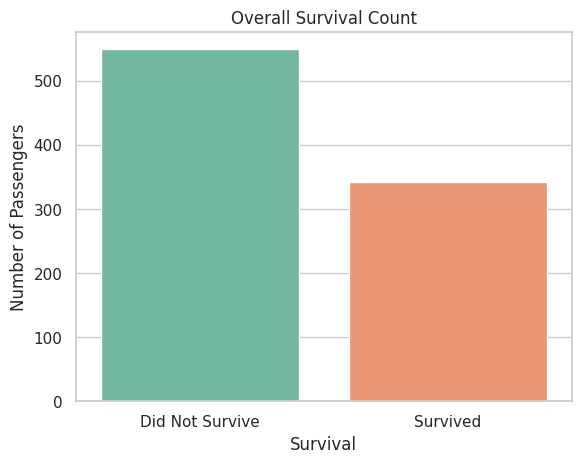

In [ ]:
# Basic countplot of survival
sns.countplot(data=titanic, x='survived', palette='Set2')
plt.title("Overall Survival Count")
plt.xticks([0, 1], ['Did Not Survive', 'Survived'])
plt.ylabel("Number of Passengers")
plt.xlabel("Survival")
plt.show()

###Survival by Categorical Features

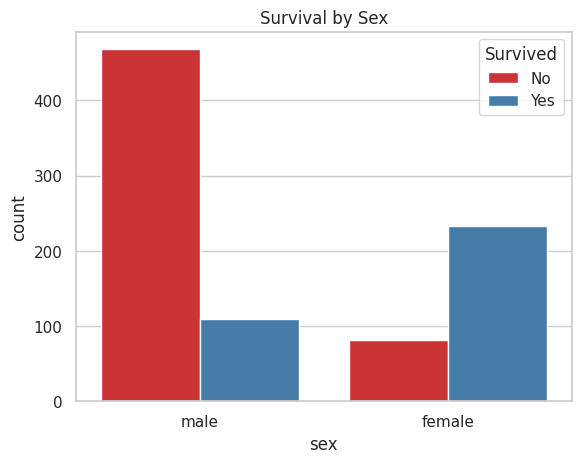

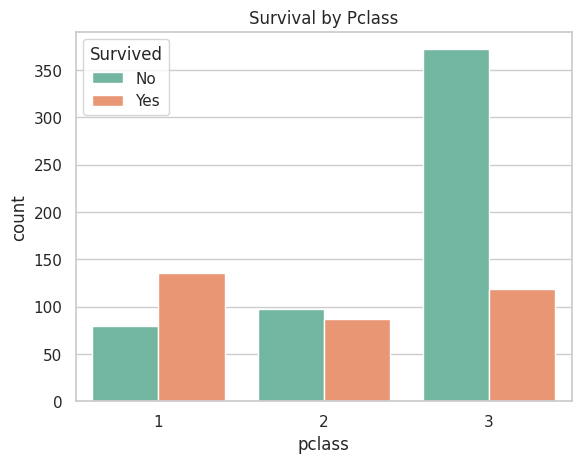

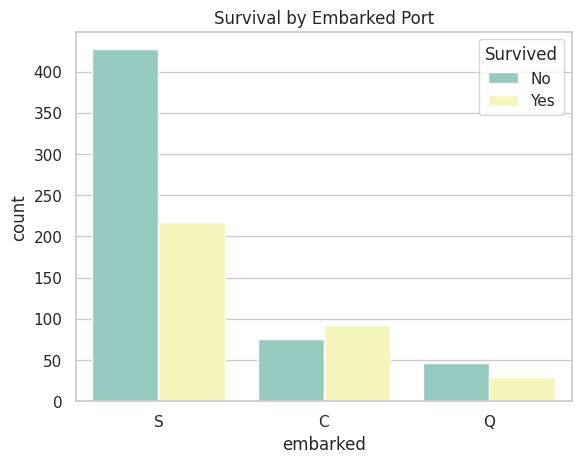

In [ ]:
# Survival vs Sex
sns.countplot(data=titanic, x='sex', hue='survived', palette='Set1')
plt.title("Survival by Sex")
plt.legend(title='Survived', labels=['No', 'Yes'])
plt.show()

# Survival vs Pclass
sns.countplot(data=titanic, x='pclass', hue='survived', palette='Set2')
plt.title("Survival by Pclass")
plt.legend(title='Survived', labels=['No', 'Yes'])
plt.show()

# Survival vs Embarked
sns.countplot(data=titanic, x='embarked', hue='survived', palette='Set3')
plt.title("Survival by Embarked Port")
plt.legend(title='Survived', labels=['No', 'Yes'])
plt.show()

###Survival by Numerical Features

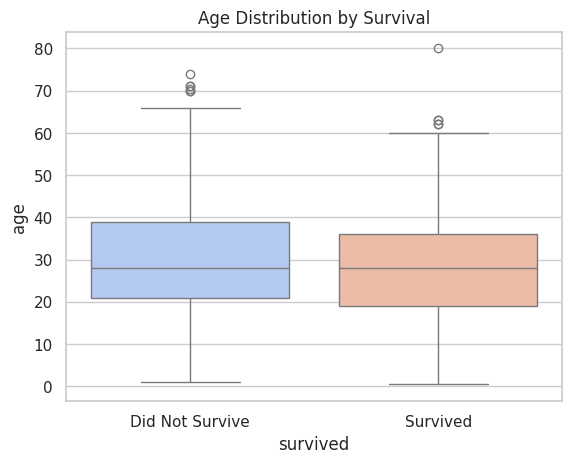

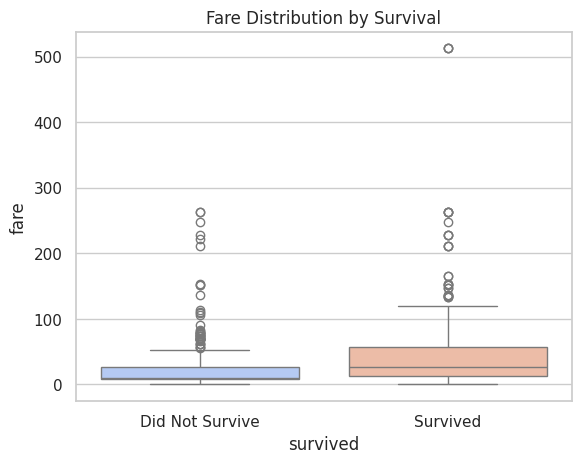

In [ ]:
# Boxplot: Age vs Survived
sns.boxplot(data=titanic, x='survived', y='age', palette='coolwarm')
plt.title("Age Distribution by Survival")
plt.xticks([0, 1], ['Did Not Survive', 'Survived'])
plt.show()

# Boxplot: Fare vs Survived
sns.boxplot(data=titanic, x='survived', y='fare', palette='coolwarm')
plt.title("Fare Distribution by Survival")
plt.xticks([0, 1], ['Did Not Survive', 'Survived'])
plt.show()

The bivariate analysis reveals strong associations between certain features and survival on the Titanic. Gender played a critical role: a majority of females survived, whereas most males perished, highlighting a clear gender bias in rescue prioritization. Passenger class (Pclass) also showed a notable effect — first-class passengers had the highest survival rate, while third-class passengers had the lowest, suggesting socioeconomic status significantly influenced survival chances. The fare distribution corroborates this, as survivors tended to have paid higher fares on average, reinforcing the advantage of wealth. Age distribution by survival shows that while there is no sharp divide, survivors were slightly younger on average, with a wider age range among those who survived. Embarkation point also had an impact: passengers embarking from Cherbourg (C) had a higher survival rate compared to those from Southampton (S) or Queenstown (Q). Lastly, the overall survival rate shows that only about 38% of passengers survived, confirming that the majority did not. These insights highlight key demographic and socioeconomic factors that shaped survival outcomes during the disaster.

##Multivariate Analysis

In [ ]:
# Select only numeric columns for correlation
numeric_cols = titanic.select_dtypes(include=['int64', 'float64'])

# Compute correlation matrix
correlation_matrix = numeric_cols.corr()

# Display the matrix
correlation_matrix

,survived,pclass,age,sibsp,parch,fare
survived,1.000000,-0.338481,-0.077221,-0.035322,0.081629,0.257307
pclass,-0.338481,1.000000,-0.369226,0.083081,0.018443,-0.549500
age,-0.077221,-0.369226,1.000000,-0.308247,-0.189119,0.096067
sibsp,-0.035322,0.083081,-0.308247,1.000000,0.414838,0.159651
parch,0.081629,0.018443,-0.189119,0.414838,1.000000,0.216225
fare,0.257307,-0.549500,0.096067,0.159651,0.216225,1.000000


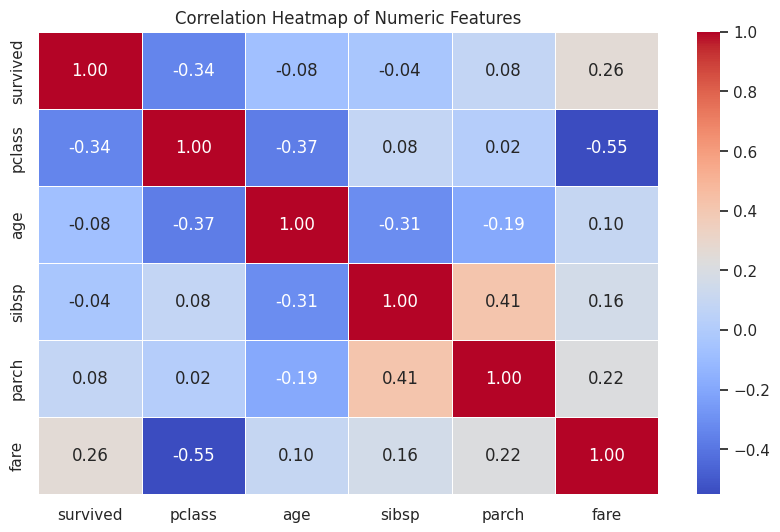

In [ ]:
# Set figure size and plot heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm", linewidths=0.5)
plt.title("Correlation Heatmap of Numeric Features")
plt.show()

The correlation matrix reveals key relationships between numerical features and the target variable, survived. The most notable positive correlation is between fare and survival (0.26), suggesting that passengers who paid higher fares — often in higher classes — had better chances of survival. Conversely, passenger class (pclass) shows a moderate negative correlation with survival (-0.34), reinforcing the earlier finding that those in third class (higher pclass number) were less likely to survive. Other variables like age, sibsp, and parch exhibit weak correlations with survival, indicating limited direct influence. Among predictors, pclass and fare are strongly negatively correlated (-0.55), which is intuitive since higher classes paid higher fares. Additionally, sibsp and parch are positively correlated (0.41), meaning passengers with siblings/spouses often also had parents/children aboard. Overall, this matrix supports the hypothesis that economic status (via pclass and fare) played a significant role in survival, more so than age or family relationships alone.

#Data Preprocessing (Baseline - Unscaled)

##Missing Values

In [ ]:
# Ensure fresh reload for rerun safety (optional, if dataset is gone)
# titanic = sns.load_dataset('titanic')

# Fill missing 'age' values with the median
titanic['age'].fillna(titanic['age'].median(), inplace=True)

# Fill missing 'embarked' values with the mode — only do this if column exists
if 'embarked' in titanic.columns:
    titanic['embarked'].fillna(titanic['embarked'].mode()[0], inplace=True)

# Drop columns (AFTER missing value handling)
cols_to_drop = ['deck', 'embark_town', 'alive', 'class', 'who', 'adult_male']
titanic.drop(columns=[col for col in cols_to_drop if col in titanic.columns], inplace=True)

# Check for any remaining missing values
titanic.isnull().sum()

,0
survived,0
pclass,0
sex,0
age,0
sibsp,0
parch,0
fare,0
embarked,0
alone,0


In [ ]:
# Encode 'sex': male = 0, female = 1
titanic['sex'] = titanic['sex'].map({'male': 0, 'female': 1})

# One-hot encode 'embarked', dropping first to avoid multicollinearity
titanic = pd.get_dummies(titanic, columns=['embarked'], drop_first=True)

In [ ]:
titanic['family_size'] = titanic['sibsp'] + titanic['parch']

# Display the final structure of the dataset
titanic.head()

,survived,pclass,sex,age,sibsp,parch,fare,alone,embarked_Q,embarked_S,family_size
0,0,3,0,22.0,1,0,7.2500,False,False,True,1
1,1,1,1,38.0,1,0,71.2833,False,False,False,1
2,1,3,1,26.0,0,0,7.9250,True,False,True,0
3,1,1,1,35.0,1,0,53.1000,False,False,True,1
4,0,3,0,35.0,0,0,8.0500,True,False,True,0


##Logistic Regression (Baseline – Unscaled)

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

# Separate features and target
X = titanic.drop('survived', axis=1)
y = titanic['survived']

# Split into training and test sets (80/20)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Initialize and train model
log_reg = LogisticRegression(random_state=42)
log_reg.fit(X_train, y_train)

LogisticRegression(random_state=42)

Accuracy: 0.7932960893854749
Precision: 0.7666666666666667
Recall: 0.6666666666666666
F1 Score: 0.7131782945736435

Classification Report:
               precision    recall  f1-score   support

           0       0.81      0.87      0.84       110
           1       0.77      0.67      0.71        69

    accuracy                           0.79       179
   macro avg       0.79      0.77      0.78       179
weighted avg       0.79      0.79      0.79       179



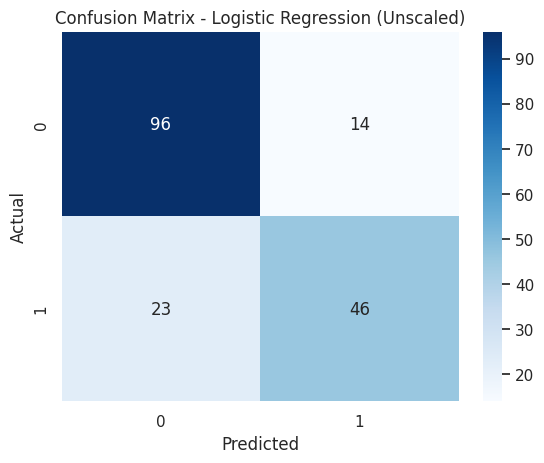

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report, roc_auc_score, roc_curve

# Predict on test set
y_pred = log_reg.predict(X_test)
y_prob = log_reg.predict_proba(X_test)[:, 1]  # Probabilities for ROC

# Metrics
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title("Confusion Matrix - Logistic Regression (Unscaled)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

###ROC Curve and AUC

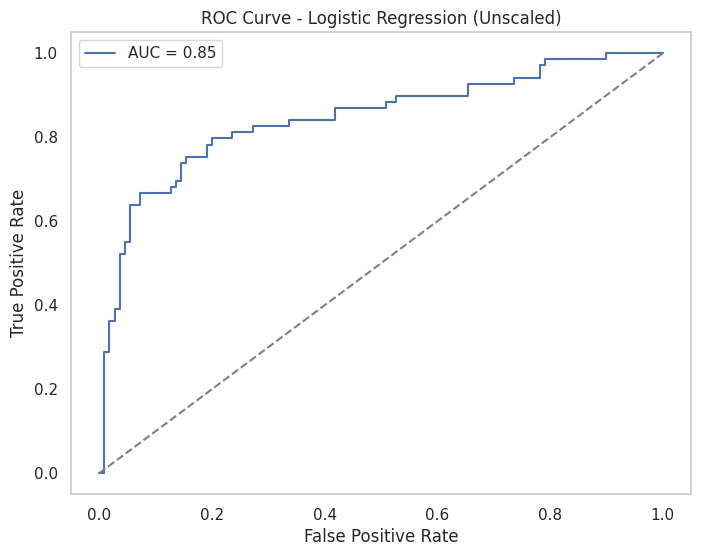

In [ ]:
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
auc_score = roc_auc_score(y_test, y_prob)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f'AUC = {auc_score:.2f}')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Logistic Regression (Unscaled)')
plt.legend()
plt.grid()
plt.show()

##Decision Tree Classifier (Baseline – Unscaled)

Accuracy: 0.7988826815642458
Precision: 0.746268656716418
Recall: 0.7246376811594203
F1 Score: 0.7352941176470589

Classification Report:
               precision    recall  f1-score   support

           0       0.83      0.85      0.84       110
           1       0.75      0.72      0.74        69

    accuracy                           0.80       179
   macro avg       0.79      0.79      0.79       179
weighted avg       0.80      0.80      0.80       179



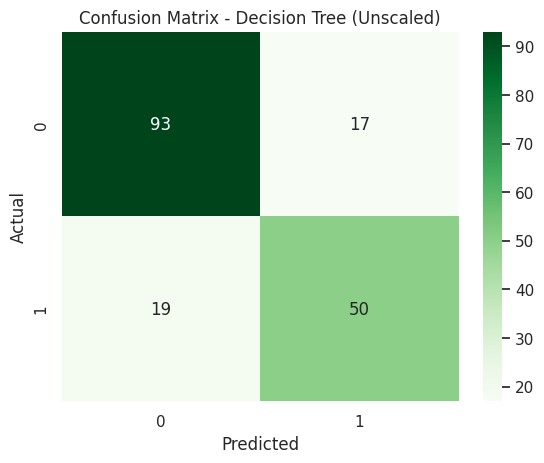

In [ ]:
from sklearn.tree import DecisionTreeClassifier

# Initialize and train decision tree
dtree = DecisionTreeClassifier(random_state=42)
dtree.fit(X_train, y_train)

# Predict on test set
y_pred_tree = dtree.predict(X_test)
y_prob_tree = dtree.predict_proba(X_test)[:, 1]

# Metrics
print("Accuracy:", accuracy_score(y_test, y_pred_tree))
print("Precision:", precision_score(y_test, y_pred_tree))
print("Recall:", recall_score(y_test, y_pred_tree))
print("F1 Score:", f1_score(y_test, y_pred_tree))
print("\nClassification Report:\n", classification_report(y_test, y_pred_tree))

# Confusion Matrix
cm_tree = confusion_matrix(y_test, y_pred_tree)
sns.heatmap(cm_tree, annot=True, fmt='d', cmap='Greens')
plt.title("Confusion Matrix - Decision Tree (Unscaled)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

###ROC Curve and AUC

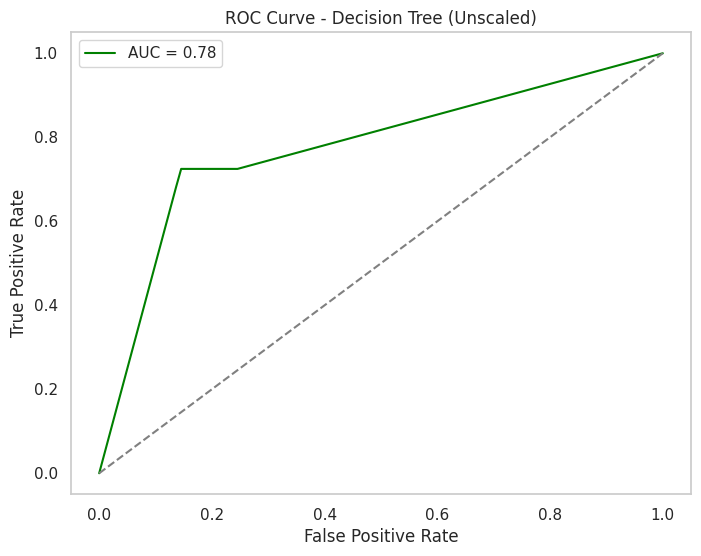

In [ ]:
fpr_tree, tpr_tree, _ = roc_curve(y_test, y_prob_tree)
auc_tree = roc_auc_score(y_test, y_prob_tree)

plt.figure(figsize=(8, 6))
plt.plot(fpr_tree, tpr_tree, label=f'AUC = {auc_tree:.2f}', color='green')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Decision Tree (Unscaled)')
plt.legend()
plt.grid()
plt.show()

##Gaussian Naive Bayes (Baseline – Unscaled)

Accuracy: 0.7821229050279329
Precision: 0.7142857142857143
Recall: 0.7246376811594203
F1 Score: 0.7194244604316546

Classification Report:
               precision    recall  f1-score   support

           0       0.83      0.82      0.82       110
           1       0.71      0.72      0.72        69

    accuracy                           0.78       179
   macro avg       0.77      0.77      0.77       179
weighted avg       0.78      0.78      0.78       179



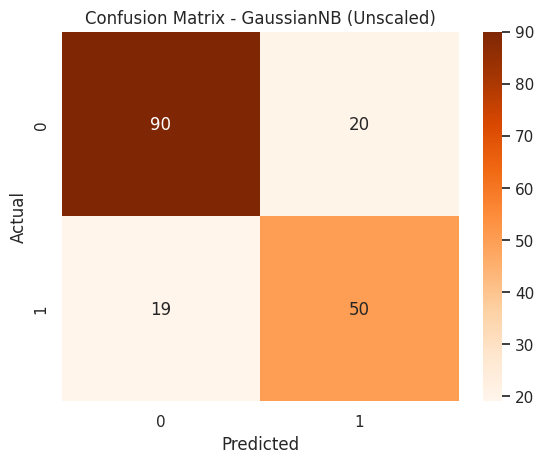

In [ ]:
from sklearn.naive_bayes import GaussianNB

# Initialize and train Gaussian Naive Bayes
gnb = GaussianNB()
gnb.fit(X_train, y_train)

# Predict on test set
y_pred_gnb = gnb.predict(X_test)
y_prob_gnb = gnb.predict_proba(X_test)[:, 1]

# Metrics
print("Accuracy:", accuracy_score(y_test, y_pred_gnb))
print("Precision:", precision_score(y_test, y_pred_gnb))
print("Recall:", recall_score(y_test, y_pred_gnb))
print("F1 Score:", f1_score(y_test, y_pred_gnb))
print("\nClassification Report:\n", classification_report(y_test, y_pred_gnb))

# Confusion Matrix
cm_gnb = confusion_matrix(y_test, y_pred_gnb)
sns.heatmap(cm_gnb, annot=True, fmt='d', cmap='Oranges')
plt.title("Confusion Matrix - GaussianNB (Unscaled)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

###ROC Curve and AUC

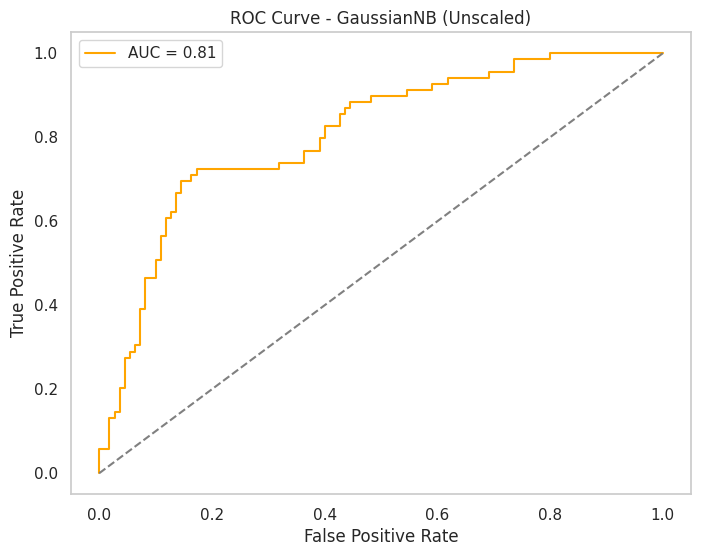

In [ ]:
fpr_gnb, tpr_gnb, _ = roc_curve(y_test, y_prob_gnb)
auc_gnb = roc_auc_score(y_test, y_prob_gnb)

plt.figure(figsize=(8, 6))
plt.plot(fpr_gnb, tpr_gnb, label=f'AUC = {auc_gnb:.2f}', color='orange')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - GaussianNB (Unscaled)')
plt.legend()
plt.grid()
plt.show()

##LASSO (Baseline – Unscaled)

Accuracy: 0.8100558659217877
Precision: 0.7966101694915254
Recall: 0.6811594202898551
F1 Score: 0.734375

Classification Report:
               precision    recall  f1-score   support

           0       0.82      0.89      0.85       110
           1       0.80      0.68      0.73        69

    accuracy                           0.81       179
   macro avg       0.81      0.79      0.79       179
weighted avg       0.81      0.81      0.81       179



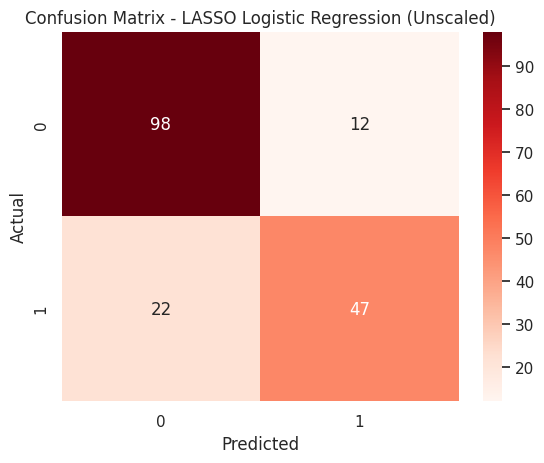

In [ ]:
from sklearn.linear_model import LogisticRegression

# LASSO (L1) Logistic Regression
lasso = LogisticRegression(penalty='l1', solver='liblinear', C=1.0, random_state=42)
lasso.fit(X_train, y_train)

# Predict on test set
y_pred_lasso = lasso.predict(X_test)
y_prob_lasso = lasso.predict_proba(X_test)[:, 1]

# Metrics
print("Accuracy:", accuracy_score(y_test, y_pred_lasso))
print("Precision:", precision_score(y_test, y_pred_lasso))
print("Recall:", recall_score(y_test, y_pred_lasso))
print("F1 Score:", f1_score(y_test, y_pred_lasso))
print("\nClassification Report:\n", classification_report(y_test, y_pred_lasso))

# Confusion Matrix
cm_lasso = confusion_matrix(y_test, y_pred_lasso)
sns.heatmap(cm_lasso, annot=True, fmt='d', cmap='Reds')
plt.title("Confusion Matrix - LASSO Logistic Regression (Unscaled)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

###ROC Curve and AUC

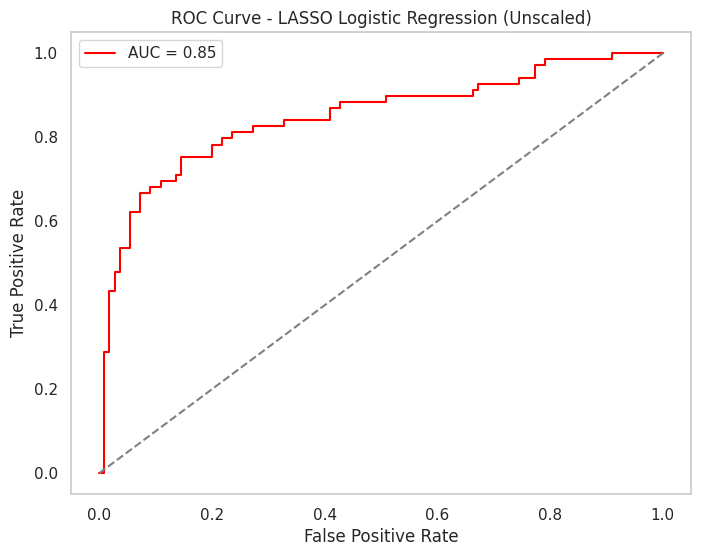

In [ ]:
fpr_lasso, tpr_lasso, _ = roc_curve(y_test, y_prob_lasso)
auc_lasso = roc_auc_score(y_test, y_prob_lasso)

plt.figure(figsize=(8, 6))
plt.plot(fpr_lasso, tpr_lasso, label=f'AUC = {auc_lasso:.2f}', color='red')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - LASSO Logistic Regression (Unscaled)')
plt.legend()
plt.grid()
plt.show()

##K-Nearest Neighbors (Baseline - Unscaled)


Accuracy: 0.6759776536312849
Precision: 0.5873015873015873
Recall: 0.5362318840579711
F1 Score: 0.5606060606060606

Classification Report:
               precision    recall  f1-score   support

           0       0.72      0.76      0.74       110
           1       0.59      0.54      0.56        69

    accuracy                           0.68       179
   macro avg       0.66      0.65      0.65       179
weighted avg       0.67      0.68      0.67       179



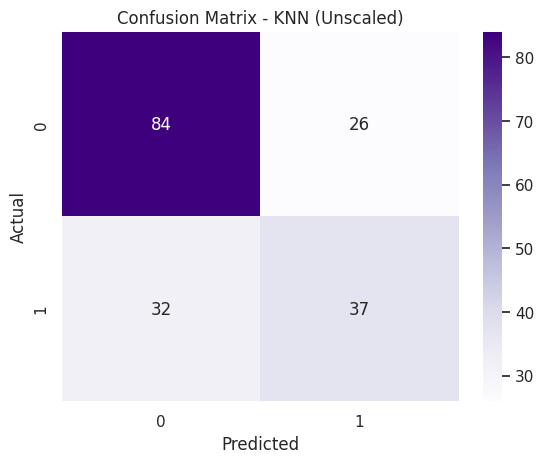

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

# Initialize and train KNN (default k=5)
knn_unscaled = KNeighborsClassifier(n_neighbors=5)
knn_unscaled.fit(X_train, y_train)

# Predict on unscaled test data
y_pred_knn_unscaled = knn_unscaled.predict(X_test)
y_prob_knn_unscaled = knn_unscaled.predict_proba(X_test)[:, 1]

# Metrics
print("Accuracy:", accuracy_score(y_test, y_pred_knn_unscaled))
print("Precision:", precision_score(y_test, y_pred_knn_unscaled))
print("Recall:", recall_score(y_test, y_pred_knn_unscaled))
print("F1 Score:", f1_score(y_test, y_pred_knn_unscaled))
print("\nClassification Report:\n", classification_report(y_test, y_pred_knn_unscaled))

# Confusion Matrix
cm_knn_unscaled = confusion_matrix(y_test, y_pred_knn_unscaled)
sns.heatmap(cm_knn_unscaled, annot=True, fmt='d', cmap='Purples')
plt.title("Confusion Matrix - KNN (Unscaled)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

###ROC Curve and AUC

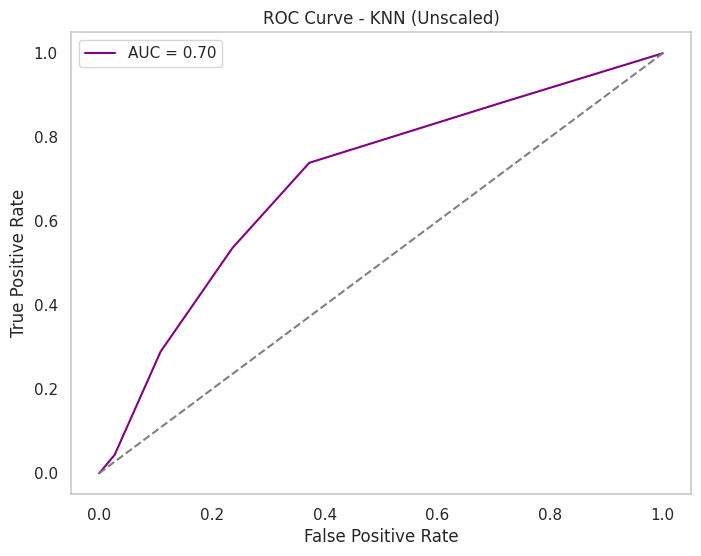

In [ ]:
fpr_knn_unscaled, tpr_knn_unscaled, _ = roc_curve(y_test, y_prob_knn_unscaled)
auc_knn_unscaled = roc_auc_score(y_test, y_prob_knn_unscaled)

plt.figure(figsize=(8, 6))
plt.plot(fpr_knn_unscaled, tpr_knn_unscaled, label=f'AUC = {auc_knn_unscaled:.2f}', color='purple')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - KNN (Unscaled)')
plt.legend()
plt.grid()
plt.show()

In evaluating the unscaled models for predicting Titanic passenger survival, LASSO Logistic Regression emerged as the top-performing model with an accuracy of 81.1%, the highest among all, and strong precision and F1 score values (≈0.80 and 0.73 respectively). It effectively minimized false positives while maintaining a good recall rate, making it especially reliable at identifying passengers who did not survive, without sacrificing too much ability to correctly predict survivors. The Decision Tree classifier followed closely, showing a balanced trade-off between precision (0.75) and recall (0.72), with an overall accuracy of 79.9%, indicating its strength in capturing survivors more accurately than standard logistic regression. Gaussian Naive Bayes also performed competitively with an accuracy of 78.2%, displaying strong recall (0.72) and moderate precision (0.71), suggesting it could be a good model in cases where identifying survivors is prioritized over minimizing false positives. Standard Logistic Regression had a slightly lower recall (0.67) compared to others, though its precision remained solid (0.77), yielding an overall accuracy of 79.3%, making it a stable baseline. On the other hand, K-Nearest Neighbors (KNN) performed the worst with an accuracy of only 67.6%, along with the lowest precision (0.59) and recall (0.54). This underperformance highlights KNN's dependence on feature scaling, as it failed to effectively distinguish between classes without normalized input. Overall, while multiple models provided competitive results without scaling, KNN notably suffered, reinforcing the need to revisit model performance after applying feature scaling.

#Feature Selection

##Feature Selection using KBest

###All Features

In [ ]:
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.pipeline import Pipeline

# All features (no real selection)
k_all = SelectKBest(score_func=f_classif, k='all')
pipeline_all = Pipeline([
    ('select', k_all),
    ('model', LogisticRegression(max_iter=1000))
])

pipeline_all.fit(X_train, y_train)
y_pred_all = pipeline_all.predict(X_test)
y_prob_all = pipeline_all.predict_proba(X_test)[:, 1]

print("K = All Features")
print("Accuracy:", accuracy_score(y_test, y_pred_all))
print("AUC:", roc_auc_score(y_test, y_prob_all))

K = All Features
Accuracy: 0.8044692737430168
AUC: 0.8512516469038208


###K=8

In [ ]:
k_8 = SelectKBest(score_func=f_classif, k=8)
pipeline_8 = Pipeline([
    ('select', k_8),
    ('model', LogisticRegression(max_iter=1000))
])

pipeline_8.fit(X_train, y_train)
y_pred_8 = pipeline_8.predict(X_test)
y_prob_8 = pipeline_8.predict_proba(X_test)[:, 1]

print("K = 8 Features")
print("Accuracy:", accuracy_score(y_test, y_pred_8))
print("AUC:", roc_auc_score(y_test, y_prob_8))

K = 8 Features
Accuracy: 0.7653631284916201
AUC: 0.8317523056653491


###K=6

In [ ]:
k_6 = SelectKBest(score_func=f_classif, k=6)
pipeline_6 = Pipeline([
    ('select', k_6),
    ('model', LogisticRegression(max_iter=1000))
])

pipeline_6.fit(X_train, y_train)
y_pred_6 = pipeline_6.predict(X_test)
y_prob_6 = pipeline_6.predict_proba(X_test)[:, 1]

print("K = 6 Features")
print("Accuracy:", accuracy_score(y_test, y_pred_6))
print("AUC:", roc_auc_score(y_test, y_prob_6))

K = 6 Features
Accuracy: 0.7821229050279329
AUC: 0.8234519104084321


###K=4

In [ ]:
k_4 = SelectKBest(score_func=f_classif, k=4)
pipeline_4 = Pipeline([
    ('select', k_4),
    ('model', LogisticRegression(max_iter=1000))
])

pipeline_4.fit(X_train, y_train)
y_pred_4 = pipeline_4.predict(X_test)
y_prob_4 = pipeline_4.predict_proba(X_test)[:, 1]

print("K = 4 Features")
print("Accuracy:", accuracy_score(y_test, y_pred_4))
print("AUC:", roc_auc_score(y_test, y_prob_4))

K = 4 Features
Accuracy: 0.776536312849162
AUC: 0.8197628458498023


###K=2

In [ ]:
k_2 = SelectKBest(score_func=f_classif, k=2)
pipeline_2 = Pipeline([
    ('select', k_2),
    ('model', LogisticRegression(max_iter=1000))
])

pipeline_2.fit(X_train, y_train)
y_pred_2 = pipeline_2.predict(X_test)
y_prob_2 = pipeline_2.predict_proba(X_test)[:, 1]

print("K = 2 Features")
print("Accuracy:", accuracy_score(y_test, y_pred_2))
print("AUC:", roc_auc_score(y_test, y_prob_2))

K = 2 Features
Accuracy: 0.776536312849162
AUC: 0.82167325428195


###K=1

In [ ]:
k_1 = SelectKBest(score_func=f_classif, k=1)
pipeline_1 = Pipeline([
    ('select', k_1),
    ('model', LogisticRegression(max_iter=1000))
])

pipeline_1.fit(X_train, y_train)
y_pred_1 = pipeline_1.predict(X_test)
y_prob_1 = pipeline_1.predict_proba(X_test)[:, 1]

print("K = 1 Feature")
print("Accuracy:", accuracy_score(y_test, y_pred_1))
print("AUC:", roc_auc_score(y_test, y_prob_1))

K = 1 Feature
Accuracy: 0.776536312849162
AUC: 0.7533596837944663


##LASSO Feature Selection


###Alpha = 1

In [ ]:
lasso_c1 = LogisticRegression(penalty='l1', solver='liblinear', C=1.0, random_state=42)
lasso_c1.fit(X_train, y_train)

# Prediction and evaluation
y_pred_c1 = lasso_c1.predict(X_test)
y_prob_c1 = lasso_c1.predict_proba(X_test)[:, 1]

print("LASSO (C = 1.0)")
print("Accuracy:", accuracy_score(y_test, y_pred_c1))
print("AUC:", roc_auc_score(y_test, y_prob_c1))

# Non-zero coefficients
features_c1 = X_train.columns
nonzero_c1 = features_c1[lasso_c1.coef_[0] != 0]
print("Selected Features:", list(nonzero_c1))

LASSO (C = 1.0)
Accuracy: 0.8100558659217877
AUC: 0.8486166007905139
Selected Features: ['pclass', 'sex', 'age', 'sibsp', 'fare', 'alone', 'embarked_Q', 'embarked_S', 'family_size']


###Alpha = 0.15


In [ ]:
lasso_c015 = LogisticRegression(penalty='l1', solver='liblinear', C=0.15, random_state=42)
lasso_c015.fit(X_train, y_train)

y_pred_c015 = lasso_c015.predict(X_test)
y_prob_c015 = lasso_c015.predict_proba(X_test)[:, 1]

print("LASSO (C = 0.15)")
print("Accuracy:", accuracy_score(y_test, y_pred_c015))
print("AUC:", roc_auc_score(y_test, y_prob_c015))

nonzero_c015 = features_c1[lasso_c015.coef_[0] != 0]
print("Selected Features:", list(nonzero_c015))

LASSO (C = 0.15)
Accuracy: 0.7932960893854749
AUC: 0.8375494071146244
Selected Features: ['pclass', 'sex', 'age', 'sibsp', 'fare', 'family_size']


###Alpha = 0.01

In [ ]:
lasso_c001 = LogisticRegression(penalty='l1', solver='liblinear', C=0.01, random_state=42)
lasso_c001.fit(X_train, y_train)

y_pred_c001 = lasso_c001.predict(X_test)
y_prob_c001 = lasso_c001.predict_proba(X_test)[:, 1]

print("LASSO (C = 0.01)")
print("Accuracy:", accuracy_score(y_test, y_pred_c001))
print("AUC:", roc_auc_score(y_test, y_prob_c001))

nonzero_c001 = features_c1[lasso_c001.coef_[0] != 0]
print("Selected Features:", list(nonzero_c001))

LASSO (C = 0.01)
Accuracy: 0.6312849162011173
AUC: 0.6204216073781291
Selected Features: ['age', 'fare']


The AUC comparison illustrates how feature selection and regularization influence model effectiveness in predicting Titanic survival. Using all features with logistic regression achieved the highest AUC (0.851), indicating that retaining the full set of variables provides the most comprehensive predictive power. However, the LASSO model with C=1.0 performed almost equally well (0.848), suggesting that regularization can effectively reduce model complexity without sacrificing much accuracy. Models using SelectKBest with 6 to 8 top features also yielded strong AUCs (0.823–0.832), showing that a thoughtfully chosen subset of features can closely match the performance of the full model. In contrast, heavily constrained models like LASSO with C=0.01 or K=1 suffered significant drops in performance (AUC as low as 0.620), likely due to excessive information loss. Overall, the results support that while more features can enhance performance, well-balanced models using moderate regularization or optimal feature selection can achieve nearly the same results with better simplicity and interpretability.

#Feature Scaling (Standardization)

In [ ]:
from sklearn.preprocessing import StandardScaler

# Copy the preprocessed dataset
titanic_scaled = titanic.copy()

# Identify numeric columns to scale
numeric_cols = ['age', 'fare', 'sibsp', 'parch', 'family_size']

# Initialize and apply scaler
scaler = StandardScaler()
titanic_scaled[numeric_cols] = scaler.fit_transform(titanic_scaled[numeric_cols])

# Define features and target on the scaled dataset
X_scaled = titanic_scaled.drop('survived', axis=1)
y_scaled = titanic_scaled['survived']

# Split into train and test sets (80/20)
X_train_scaled, X_test_scaled, y_train_scaled, y_test_scaled = train_test_split(
    X_scaled, y_scaled, test_size=0.2, random_state=42, stratify=y_scaled)

#Data Processing (Scaled)

##Logistic Regression

Accuracy: 0.8044692737430168
Precision: 0.7833333333333333
Recall: 0.6811594202898551
F1 Score: 0.7286821705426356

Classification Report:
               precision    recall  f1-score   support

           0       0.82      0.88      0.85       110
           1       0.78      0.68      0.73        69

    accuracy                           0.80       179
   macro avg       0.80      0.78      0.79       179
weighted avg       0.80      0.80      0.80       179



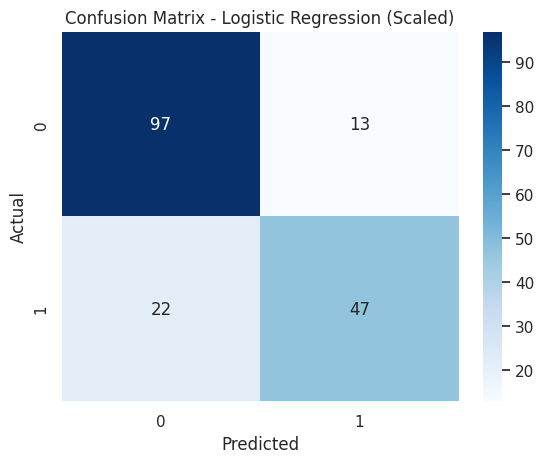

In [ ]:
# Re-initialize and fit the model
log_reg_scaled = LogisticRegression(random_state=42)
log_reg_scaled.fit(X_train_scaled, y_train_scaled)

# Predict on test set
y_pred_log_scaled = log_reg_scaled.predict(X_test_scaled)
y_prob_log_scaled = log_reg_scaled.predict_proba(X_test_scaled)[:, 1]

# Metrics
print("Accuracy:", accuracy_score(y_test_scaled, y_pred_log_scaled))
print("Precision:", precision_score(y_test_scaled, y_pred_log_scaled))
print("Recall:", recall_score(y_test_scaled, y_pred_log_scaled))
print("F1 Score:", f1_score(y_test_scaled, y_pred_log_scaled))
print("\nClassification Report:\n", classification_report(y_test_scaled, y_pred_log_scaled))

# Confusion Matrix
cm_log_scaled = confusion_matrix(y_test_scaled, y_pred_log_scaled)
sns.heatmap(cm_log_scaled, annot=True, fmt='d', cmap='Blues')
plt.title("Confusion Matrix - Logistic Regression (Scaled)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

###ROC Curve and AUC

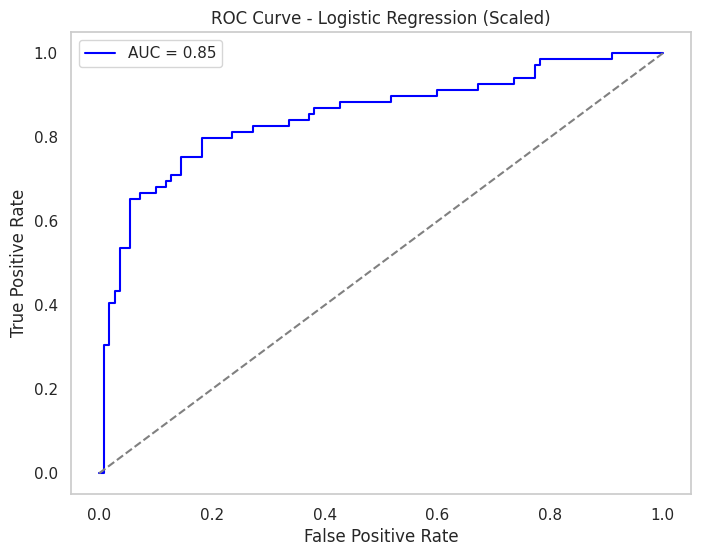

In [ ]:
fpr_log_scaled, tpr_log_scaled, _ = roc_curve(y_test_scaled, y_prob_log_scaled)
auc_log_scaled = roc_auc_score(y_test_scaled, y_prob_log_scaled)

plt.figure(figsize=(8, 6))
plt.plot(fpr_log_scaled, tpr_log_scaled, label=f'AUC = {auc_log_scaled:.2f}', color='blue')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Logistic Regression (Scaled)')
plt.legend()
plt.grid()
plt.show()

#Decision Tree (Scaled)

Accuracy: 0.8044692737430168
Precision: 0.75
Recall: 0.7391304347826086
F1 Score: 0.7445255474452555

Classification Report:
               precision    recall  f1-score   support

           0       0.84      0.85      0.84       110
           1       0.75      0.74      0.74        69

    accuracy                           0.80       179
   macro avg       0.79      0.79      0.79       179
weighted avg       0.80      0.80      0.80       179



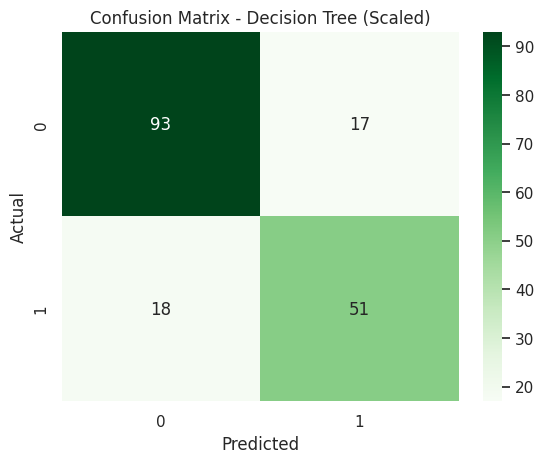

In [ ]:
# Initialize and train decision tree on scaled data
dtree_scaled = DecisionTreeClassifier(random_state=42)
dtree_scaled.fit(X_train_scaled, y_train_scaled)

# Predict on test set
y_pred_tree_scaled = dtree_scaled.predict(X_test_scaled)
y_prob_tree_scaled = dtree_scaled.predict_proba(X_test_scaled)[:, 1]

# Metrics
print("Accuracy:", accuracy_score(y_test_scaled, y_pred_tree_scaled))
print("Precision:", precision_score(y_test_scaled, y_pred_tree_scaled))
print("Recall:", recall_score(y_test_scaled, y_pred_tree_scaled))
print("F1 Score:", f1_score(y_test_scaled, y_pred_tree_scaled))
print("\nClassification Report:\n", classification_report(y_test_scaled, y_pred_tree_scaled))

# Confusion Matrix
cm_tree_scaled = confusion_matrix(y_test_scaled, y_pred_tree_scaled)
sns.heatmap(cm_tree_scaled, annot=True, fmt='d', cmap='Greens')
plt.title("Confusion Matrix - Decision Tree (Scaled)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

###ROC Curve and AUC

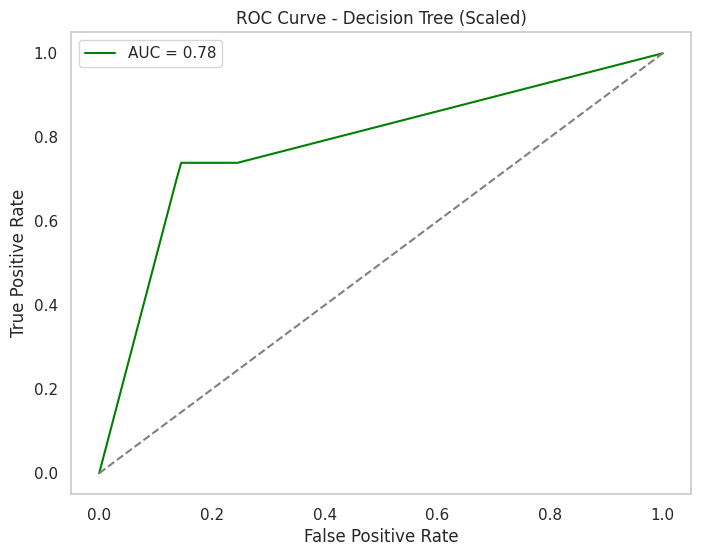

In [ ]:
fpr_tree_scaled, tpr_tree_scaled, _ = roc_curve(y_test_scaled, y_prob_tree_scaled)
auc_tree_scaled = roc_auc_score(y_test_scaled, y_prob_tree_scaled)

plt.figure(figsize=(8, 6))
plt.plot(fpr_tree_scaled, tpr_tree_scaled, label=f'AUC = {auc_tree_scaled:.2f}', color='green')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Decision Tree (Scaled)')
plt.legend()
plt.grid()
plt.show()

##Gaussian Naive Bayes (Scaled)

Accuracy: 0.7821229050279329
Precision: 0.7142857142857143
Recall: 0.7246376811594203
F1 Score: 0.7194244604316546

Classification Report:
               precision    recall  f1-score   support

           0       0.83      0.82      0.82       110
           1       0.71      0.72      0.72        69

    accuracy                           0.78       179
   macro avg       0.77      0.77      0.77       179
weighted avg       0.78      0.78      0.78       179



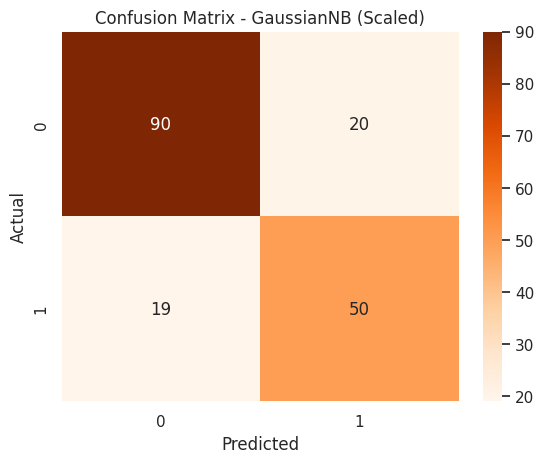

In [ ]:
# Initialize and train Gaussian Naive Bayes on scaled data
gnb_scaled = GaussianNB()
gnb_scaled.fit(X_train_scaled, y_train_scaled)

# Predict on test set
y_pred_gnb_scaled = gnb_scaled.predict(X_test_scaled)
y_prob_gnb_scaled = gnb_scaled.predict_proba(X_test_scaled)[:, 1]

# Metrics
print("Accuracy:", accuracy_score(y_test_scaled, y_pred_gnb_scaled))
print("Precision:", precision_score(y_test_scaled, y_pred_gnb_scaled))
print("Recall:", recall_score(y_test_scaled, y_pred_gnb_scaled))
print("F1 Score:", f1_score(y_test_scaled, y_pred_gnb_scaled))
print("\nClassification Report:\n", classification_report(y_test_scaled, y_pred_gnb_scaled))

# Confusion Matrix
cm_gnb_scaled = confusion_matrix(y_test_scaled, y_pred_gnb_scaled)
sns.heatmap(cm_gnb_scaled, annot=True, fmt='d', cmap='Oranges')
plt.title("Confusion Matrix - GaussianNB (Scaled)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

###ROC Curve and AUC

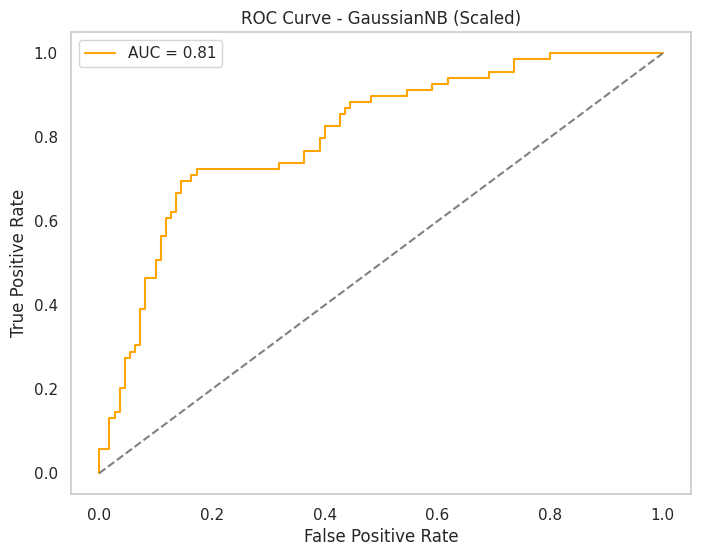

In [ ]:
fpr_gnb_scaled, tpr_gnb_scaled, _ = roc_curve(y_test_scaled, y_prob_gnb_scaled)
auc_gnb_scaled = roc_auc_score(y_test_scaled, y_prob_gnb_scaled)

plt.figure(figsize=(8, 6))
plt.plot(fpr_gnb_scaled, tpr_gnb_scaled, label=f'AUC = {auc_gnb_scaled:.2f}', color='orange')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - GaussianNB (Scaled)')
plt.legend()
plt.grid()
plt.show()

##LASSO (Scaled)

Accuracy: 0.8100558659217877
Precision: 0.7966101694915254
Recall: 0.6811594202898551
F1 Score: 0.734375

Classification Report:
               precision    recall  f1-score   support

           0       0.82      0.89      0.85       110
           1       0.80      0.68      0.73        69

    accuracy                           0.81       179
   macro avg       0.81      0.79      0.79       179
weighted avg       0.81      0.81      0.81       179



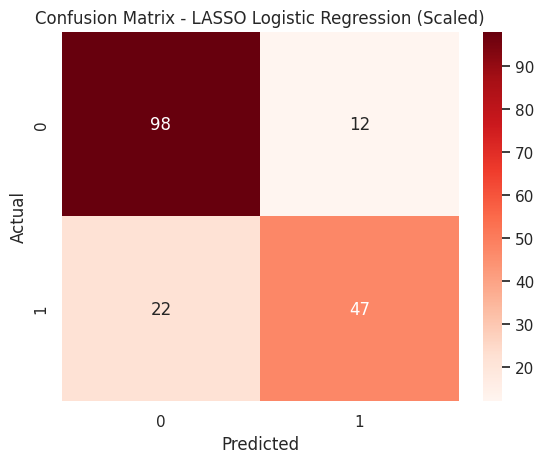

In [ ]:
# Initialize and train LASSO logistic regression on scaled data
lasso_scaled = LogisticRegression(penalty='l1', solver='liblinear', C=1.0, random_state=42)
lasso_scaled.fit(X_train_scaled, y_train_scaled)

# Predict on test set
y_pred_lasso_scaled = lasso_scaled.predict(X_test_scaled)
y_prob_lasso_scaled = lasso_scaled.predict_proba(X_test_scaled)[:, 1]

# Metrics
print("Accuracy:", accuracy_score(y_test_scaled, y_pred_lasso_scaled))
print("Precision:", precision_score(y_test_scaled, y_pred_lasso_scaled))
print("Recall:", recall_score(y_test_scaled, y_pred_lasso_scaled))
print("F1 Score:", f1_score(y_test_scaled, y_pred_lasso_scaled))
print("\nClassification Report:\n", classification_report(y_test_scaled, y_pred_lasso_scaled))

# Confusion Matrix
cm_lasso_scaled = confusion_matrix(y_test_scaled, y_pred_lasso_scaled)
sns.heatmap(cm_lasso_scaled, annot=True, fmt='d', cmap='Reds')
plt.title("Confusion Matrix - LASSO Logistic Regression (Scaled)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

###ROC Curve and AUC

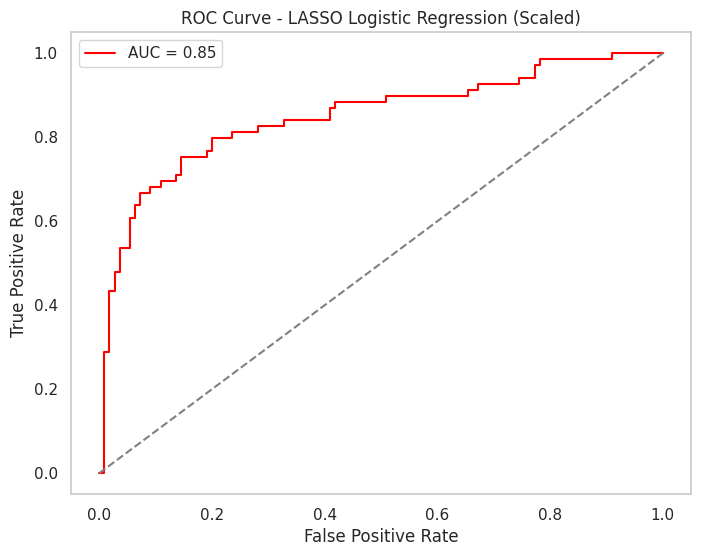

In [ ]:
fpr_lasso_scaled, tpr_lasso_scaled, _ = roc_curve(y_test_scaled, y_prob_lasso_scaled)
auc_lasso_scaled = roc_auc_score(y_test_scaled, y_prob_lasso_scaled)

plt.figure(figsize=(8, 6))
plt.plot(fpr_lasso_scaled, tpr_lasso_scaled, label=f'AUC = {auc_lasso_scaled:.2f}', color='red')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - LASSO Logistic Regression (Scaled)')
plt.legend()
plt.grid()
plt.show()

##K-Nearest Neighbors (Scaled)

Accuracy: 0.7877094972067039
Precision: 0.7627118644067796
Recall: 0.6521739130434783
F1 Score: 0.703125

Classification Report:
               precision    recall  f1-score   support

           0       0.80      0.87      0.83       110
           1       0.76      0.65      0.70        69

    accuracy                           0.79       179
   macro avg       0.78      0.76      0.77       179
weighted avg       0.79      0.79      0.78       179



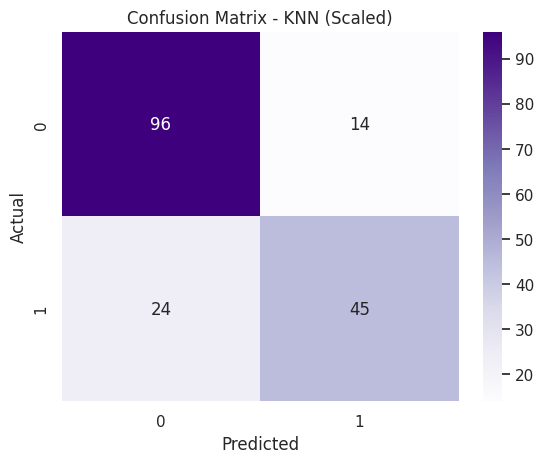

In [ ]:
# Initialize and train KNN on scaled data
knn_scaled = KNeighborsClassifier(n_neighbors=5)
knn_scaled.fit(X_train_scaled, y_train_scaled)

# Predict on test set
y_pred_knn_scaled = knn_scaled.predict(X_test_scaled)
y_prob_knn_scaled = knn_scaled.predict_proba(X_test_scaled)[:, 1]

# Metrics
print("Accuracy:", accuracy_score(y_test_scaled, y_pred_knn_scaled))
print("Precision:", precision_score(y_test_scaled, y_pred_knn_scaled))
print("Recall:", recall_score(y_test_scaled, y_pred_knn_scaled))
print("F1 Score:", f1_score(y_test_scaled, y_pred_knn_scaled))
print("\nClassification Report:\n", classification_report(y_test_scaled, y_pred_knn_scaled))

# Confusion Matrix
cm_knn_scaled = confusion_matrix(y_test_scaled, y_pred_knn_scaled)
sns.heatmap(cm_knn_scaled, annot=True, fmt='d', cmap='Purples')
plt.title("Confusion Matrix - KNN (Scaled)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

###ROC Curve and AUC

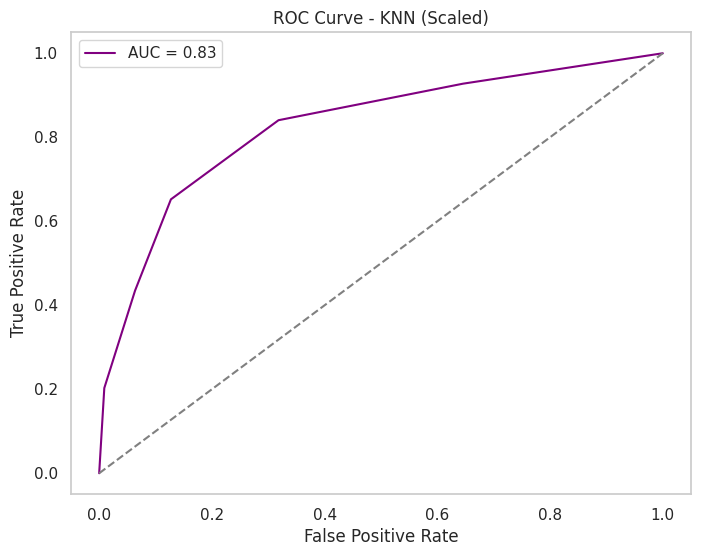

In [ ]:
fpr_knn_scaled, tpr_knn_scaled, _ = roc_curve(y_test_scaled, y_prob_knn_scaled)
auc_knn_scaled = roc_auc_score(y_test_scaled, y_prob_knn_scaled)

plt.figure(figsize=(8, 6))
plt.plot(fpr_knn_scaled, tpr_knn_scaled, label=f'AUC = {auc_knn_scaled:.2f}', color='purple')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - KNN (Scaled)')
plt.legend()
plt.grid()
plt.show()

To evaluate the classification performance of different machine learning models for predicting Titanic passenger survival, five algorithms were tested on scaled data: Decision Tree, Logistic Regression, K-Nearest Neighbors (KNN), LASSO Logistic Regression, and Gaussian Naive Bayes (GNB). All models achieved comparable overall accuracy, ranging from 78% to 81%, but nuanced differences emerged in their precision, recall, and F1-scores. LASSO Logistic Regression had the highest accuracy (81%), as well as the strongest balance of precision (0.80) and recall (0.68) for predicting survivors (class 1), yielding a solid F1-score of 0.73. The Decision Tree performed similarly, also achieving 80% accuracy, but with slightly higher recall for survivors (0.74), making it slightly better at identifying positive cases despite a small tradeoff in precision. KNN showed slightly lower performance, with an accuracy of 78.8% and the lowest recall (0.65) for survivors, suggesting it may miss more actual positive cases. Logistic Regression had a good balance (accuracy of 80.4%), though it leaned slightly toward better identifying non-survivors (higher precision for class 0). Meanwhile, GaussianNB produced the lowest overall accuracy (78.2%) but had relatively balanced precision and recall across both classes, making it a reasonable baseline model. In summary, while all models were effective, LASSO Logistic Regression and Decision Tree stood out as top performers due to their strong balance between identifying survivors and non-survivors with high accuracy and F1 scores.

#Model Comparison – ROC Curves & AUC

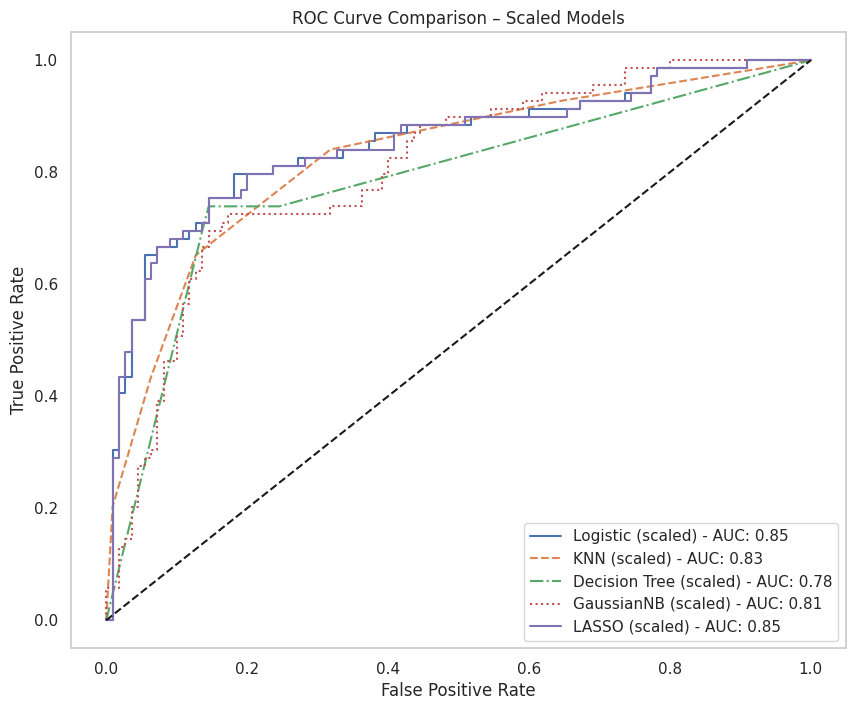

In [ ]:
plt.figure(figsize=(10, 8))

# Unscaled models
plt.plot(fpr_log_scaled, tpr_log_scaled, label=f'Logistic (scaled) - AUC: {auc_log_scaled:.2f}', linestyle='-')
plt.plot(fpr_knn_scaled, tpr_knn_scaled, label=f'KNN (scaled) - AUC: {auc_knn_scaled:.2f}', linestyle='--')
plt.plot(fpr_tree_scaled, tpr_tree_scaled, label=f'Decision Tree (scaled) - AUC: {auc_tree_scaled:.2f}', linestyle='-.')
plt.plot(fpr_gnb_scaled, tpr_gnb_scaled, label=f'GaussianNB (scaled) - AUC: {auc_gnb_scaled:.2f}', linestyle=':')
plt.plot(fpr_lasso_scaled, tpr_lasso_scaled, label=f'LASSO (scaled) - AUC: {auc_lasso_scaled:.2f}', linestyle='solid')

# Diagonal reference line
plt.plot([0, 1], [0, 1], 'k--')

plt.title("ROC Curve Comparison – Scaled Models")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc='lower right')
plt.grid()
plt.show()

#Insights & Conclusion

The goal of this case study was to build, evaluate, and compare various classification models to predict whether a passenger survived the Titanic disaster (Survived: 0 = No, 1 = Yes). Multiple models were tested, first on raw (unscaled) data and then on scaled data to examine performance changes due to preprocessing.

Data Preparation Summary:

- Missing values in age were filled with the median, and embarked was filled with the mode.
- Columns like deck, embark_town, alive, class, who, and adult_male were dropped due to redundancy or excessive missing data.
- Categorical variables (sex, embarked) were converted to numerical values using Label Encoding.
- A baseline set of models was trained without scaling, then re-trained after applying StandardScaler to observe scaling effects.

Models Evaluated:

Six classification models were tested on both unscaled and scaled data:
Logistic Regression, K-Nearest Neighbors, Decision Tree,Gaussian Naive Bayes,
& LASSO.

ROC & AUC Summary (Scaled Models):

Logistic Regression: 0.85
LASSO Regression: 0.85
K-Nearest Neighbors: 0.83
Gaussian Naive Bayes: 0.81
Decision Tree: 0.78

ROC curves showed that Logistic Regression and LASSO performed best overall, with high true positive rates and low false positives. Scaling clearly improved models like KNN, which relies on distance metrics.

Best Model: Logistic Regression (Scaled)

Logistic Regression achieved the highest AUC (0.85), with well-balanced precision, recall, and F1 score, making it a strong and interpretable choice. It also benefited greatly from scaling and performed consistently across the metrics.

Model Behavior & Trade-Offs:

- KNN was highly sensitive to scaling — unscaled performance was poor, but after scaling, its AUC jumped significantly.
- Decision Tree offered interpretability but underperformed compared to others. It may have overfit the training data.
- Naive Bayes was relatively robust but made strong assumptions about feature independence that slightly limited performance.
- LASSO added feature selection via L1 regularization and achieved high AUC, showing it’s a good choice when reducing feature space is a priority.

Final Reflections & Recommendations:
- Scaling should always be part of the preprocessing pipeline, especially for models sensitive to feature magnitudes.
- Logistic Regression is a strong baseline model and, in this case, outperformed more complex models.
- Use LASSO when working with high-dimensional data to control overfitting and improve generalization.
- Always evaluate with ROC/AUC, not just accuracy, especially when false negatives/positives have different real-world impacts.